# 1 The Business Problem
## Understanding the business problem

Telecommunications companies lose revenue when customers leave to join competitors. This is known as customer churn.

The business challenge is to identify customers who are likely to leave so the company can prioritise retention efforts, such as customer support, targeted offers, or discounts.

However, the company has limited resources. It needs a way to identify customers who may be at risk rather than spending the same amount of time and money on every customer.

The objective of this project is to build and compare machine learning models that predict whether a customer is likely to churn, using all available customer features in the dataset.

The project will compare four algorithms:

Logistic Regression
Decision Tree
Random Forest
K-Nearest Neighbours (KNN)

We'll evaluate their performance using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices

In [143]:
# Importing Libraries before work


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (7, 4)

def check(label, test, hint=""):
    """Self-check helper: prints ✅ or ❌ (with a hint)."""
    try:
        ok = bool(test())
    except Exception as e:
        ok, hint = False, f"{hint}  (error: {type(e).__name__}: {e})"
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"\n   hint: {hint}"))

print("Ready!")

Ready!


In [144]:
# 1.2 Load the data

df = pd.read_csv(r"C:\DATA SCIENCE\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [145]:
# 1.3 Inspect the dataset
df.shape

(7043, 21)

In [146]:
# Checking the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [147]:
# Checking the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [148]:
# Displaying the first five rows
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [149]:
# Displaying column names and data types
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [150]:
# The main issue: TotalCharges is a string (str), not a number. I am converting it to a numeric type
df.TotalCharges = pd.to_numeric(df.TotalCharges, errors='coerce')

In [151]:
# Identifying target variables and features
# Checking the target variable
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [152]:
# Checking the percentage of each target class
print(df["Churn"].value_counts(normalize=True) * 100)


Churn
No     73.463
Yes    26.537
Name: proportion, dtype: float64


In [153]:
# Identify unique values in the target
print(df["Churn"].unique())

<StringArray>
['No', 'Yes']
Length: 2, dtype: str


# 2 Data Cleaning


In [154]:
#2.1 Check for missing values
# Count missing values in each column
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

TotalCharges    11
dtype: int64


In [155]:
# Convert TotalCharges to numeric
# Blank or invalid entries will become NaN

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values again
print(df.isnull().sum()[df.isnull().sum() > 0])

TotalCharges    11
dtype: int64


In [156]:
#TotallCharges has ben changed to numerical but the number is 7032 instead of 7043 which implies 11 missing values
# This is 0.156% of the data set which is below 1% so it it safe to delete them
# Removing rows where the target is missing
df = df.dropna(subset=["Churn"])

print("Shape after removing missing target labels:", df.shape)

Shape after removing missing target labels: (7043, 21)


In [157]:
# Checking for duplicates
# Count completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [158]:
# Inspecting data types
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [159]:
print(df["TotalCharges"].dtype)

float64


In [160]:
# Check for unusual values and outliers
# Numerical columns to investigate
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]


In [161]:
# Summary statistics
display(df[numerical_columns].describe().T)


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371,24.559,0.00,9.00,29.000,55.000,72.00
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.350,89.850,118.75
TotalCharges,7032.0,2283.300,2266.771,18.80,401.45,1397.475,3794.738,8684.80


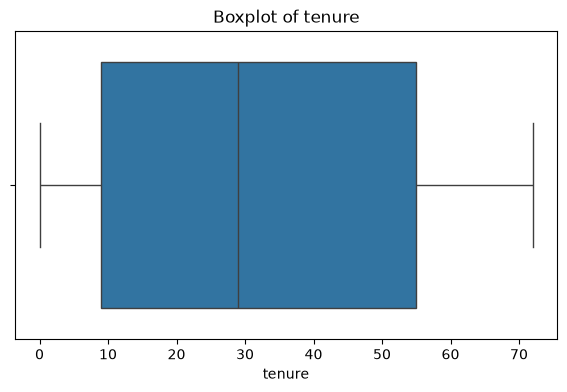

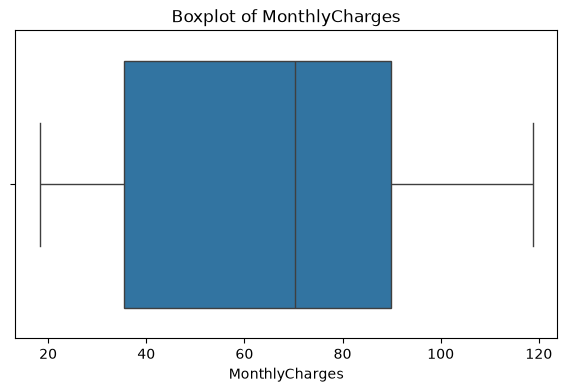

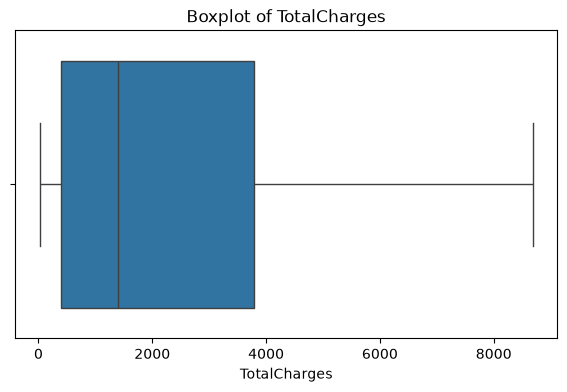

In [162]:
# Boxplots for numerical features
for column in numerical_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.show()

In [163]:
# Counting potential outliers using the IQR method
# The interquartile range method identifies values outside a statistical range.

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(
        f"{column}: {len(outliers)} potential outliers"
    )

tenure: 0 potential outliers
MonthlyCharges: 0 potential outliers
TotalCharges: 0 potential outliers


# 3 Data Visualisation

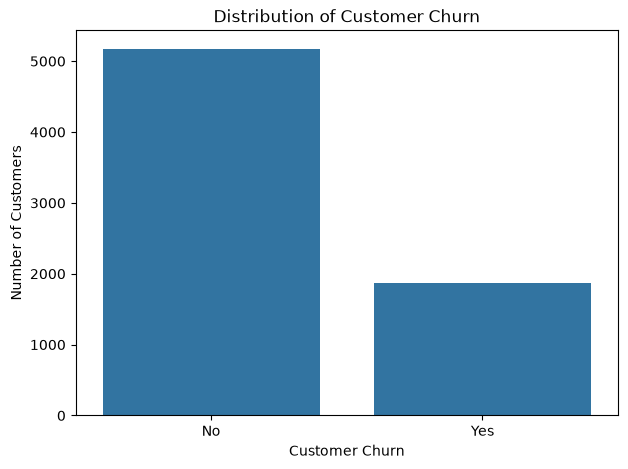

In [164]:
# Visualising the target variable
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Distribution of Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

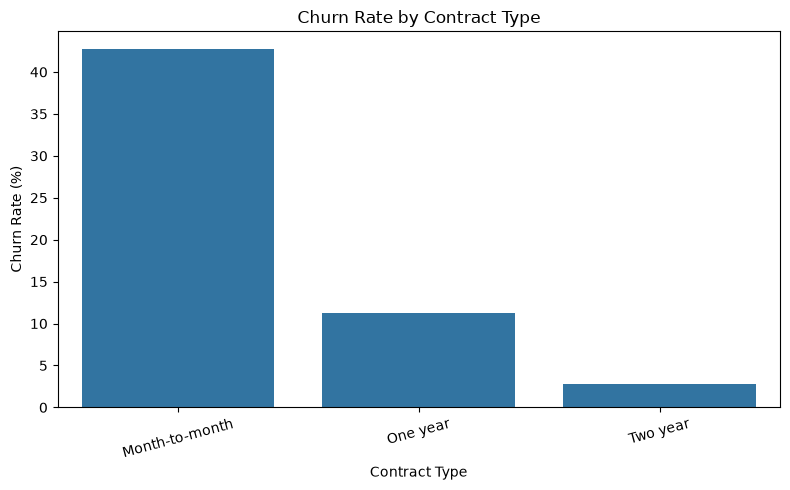

In [165]:
# Churn rate by contract type
contract_churn = (
    df.groupby("Contract", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

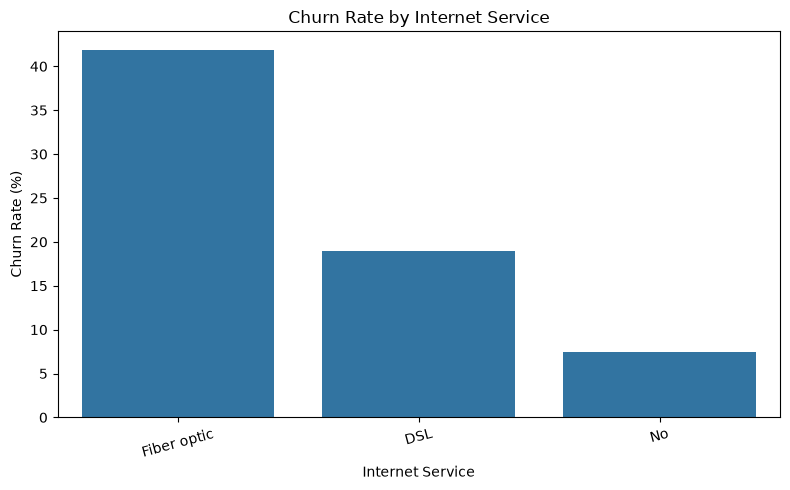

In [166]:
# Churn rate by internet service
internet_churn = (
    df.groupby("InternetService", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

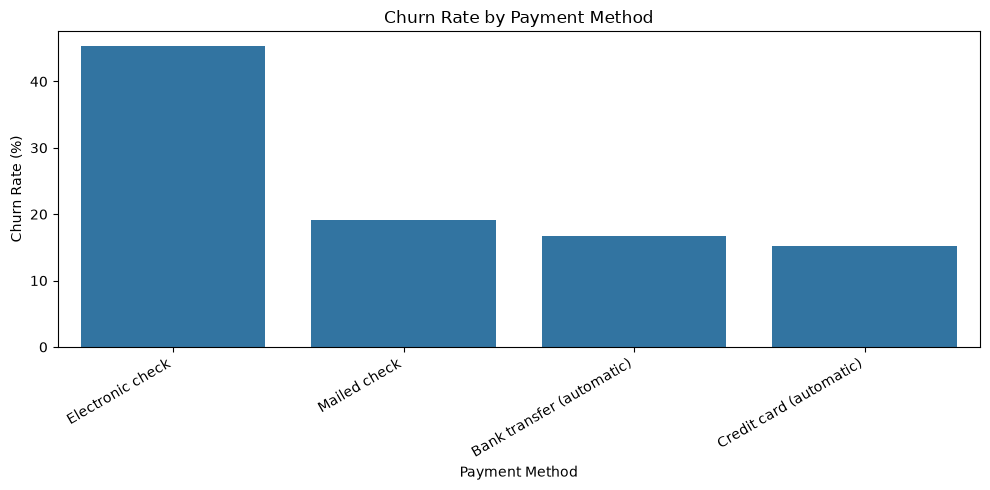

In [167]:
#Churn rate by payment method#
payment_churn = (
    df.groupby("PaymentMethod", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##Correlation heatmap

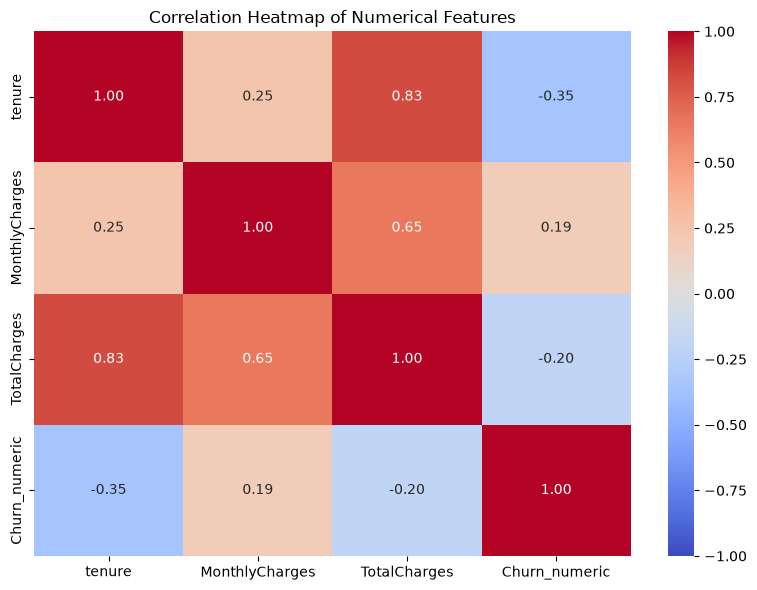

In [168]:
# Creating a numerical version of Churn for correlation analysis
df["Churn_numeric"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Selecting numerical columns
correlation_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn_numeric"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# 4 Data Preprocessing

In [169]:
# Identifying the target and input features
# Defining the target
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Removing target, identifier, and exploratory target column
X = df.drop(
    columns=["Churn", "customerID", "Churn_numeric"],
    errors="ignore"
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Feature shape: (7043, 19)
Target shape: (7043,)

Input features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [170]:
# Identifying categorical and numerical columns
# Automatically identify categorical and numerical features

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\akinl\AppData\Local\Temp\ipykernel_4436\429103524.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [171]:
# This approach means we don't have to manually type every feature name
# Spliting the data: 80% training and 20% testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining churn proportion:")
print(y_train.value_counts(normalize=True))

print("\nTesting churn proportion:")
print(y_test.value_counts(normalize=True))

Training features: (5634, 19)
Testing features: (1409, 19)
Training target: (5634,)
Testing target: (1409,)

Training churn proportion:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing churn proportion:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


##### Imputation, one-hot encoding, and scaling
I will use two preprocessing pipelines.

Categorical pipeline: 
Fill missing values using the most frequent category.
One-hot encode each category.

Numerical pipeline:
Fill missing values using the median.
Standardise the values using StandardScaler.


In [172]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Pipeline for numerical features
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_pipeline, categorical_features),
        ("numerical", numerical_pipeline, numerical_features)
    ],
    remainder="drop"
)

# 5 Problem type

This is a supervised binary classification problem.

Why classification?

We want to predict whether a customer will churn.

The target variable contains two possible outcomes:

0 = Customer stays.
1 = Customer churns.

The model learns patterns from historical customer records where the outcome is already known. It then uses those patterns to predict the outcome for other customers.

It is not a regression problem because we are not trying to predict a continuous numerical quantity such as revenue or customer lifetime value.

In [173]:
# Confirming my target Classes
print(y.value_counts())

print("\nTarget classes:")
print(y.unique())

Churn
0    5174
1    1869
Name: count, dtype: int64

Target classes:
[0 1]


# 6 Model Comparison
i will train and compare four chosen algorithms using the same 80/20 split.

The models are:

Logistic Regression
Decision Tree
Random Forest
K-Nearest Neighbours

For a fair comparison, each model will use the same training records and the same test records, with preprocessing fitted independently within each model's pipeline.

In [174]:
# Defining my models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Defining the four algorithms
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "K-Nearest Neighbours": KNeighborsClassifier(
        n_neighbors=5
    )
}

# Combining preprocessing and each classifier
pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

Why use pipelines?

A pipeline ensures that each model uses the same preprocessing logic and that transformations are fitted only on its training data.

It also makes later cross-validation and hyperparameter tuning easier

In [175]:
# Trainning and evaluating the models
# Calculating all Metric

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

results = []
confusion_matrices = {}

for name, pipeline in pipelines.items():

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predictions on training data
    y_train_pred = pipeline.predict(X_train)

    # Predictions on test data
    y_test_pred = pipeline.predict(X_test)

    # Predicted probabilities for ROC-AUC
    y_train_proba = pipeline.predict_proba(X_train)[:, 1]
    y_test_proba = pipeline.predict_proba(X_test)[:, 1]

    # Calculate training metrics
    train_accuracy = accuracy_score(y_train, y_train_pred)

    train_precision = precision_score(
        y_train,
        y_train_pred,
        zero_division=0
    )

    train_recall = recall_score(
        y_train,
        y_train_pred,
        zero_division=0
    )

    train_f1 = f1_score(
        y_train,
        y_train_pred,
        zero_division=0
    )

    train_roc_auc = roc_auc_score(
        y_train,
        y_train_proba
    )

    # Calculate testing metrics
    test_accuracy = accuracy_score(y_test, y_test_pred)

    test_precision = precision_score(
        y_test,
        y_test_pred,
        zero_division=0
    )

    test_recall = recall_score(
        y_test,
        y_test_pred,
        zero_division=0
    )

    test_f1 = f1_score(
        y_test,
        y_test_pred,
        zero_division=0
    )

    test_roc_auc = roc_auc_score(
        y_test,
        y_test_proba
    )

    # Calculate confusion matrix on the test set
    cm = confusion_matrix(
        y_test,
        y_test_pred,
        labels=[0, 1]
    )

    confusion_matrices[name] = cm

    # Store the results
    results.append({
        "Algorithm": name,

        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Accuracy Gap": train_accuracy - test_accuracy,

        "Train Precision": train_precision,
        "Test Precision": test_precision,
        "Precision Gap": train_precision - test_precision,

        "Train Recall": train_recall,
        "Test Recall": test_recall,
        "Recall Gap": train_recall - test_recall,

        "Train F1": train_f1,
        "Test F1": test_f1,
        "F1 Gap": train_f1 - test_f1,

        "Train ROC-AUC": train_roc_auc,
        "Test ROC-AUC": test_roc_auc,
        "ROC-AUC Gap": train_roc_auc - test_roc_auc
    })

# Create a results DataFrame
results_df = pd.DataFrame(results)

# Sort by test recall to prioritise identifying churners
results_df = results_df.sort_values(
    by="Test Recall",
    ascending=False
)

# Display results
display(results_df.round(3))

,Algorithm,Train Accuracy,Test Accuracy,Accuracy Gap,Train Precision,Test Precision,Precision Gap,Train Recall,Test Recall,Recall Gap,Train F1,Test F1,F1 Gap,Train ROC-AUC,Test ROC-AUC,ROC-AUC Gap
3,K-Nearest Neighbours,0.837,0.764,0.073,0.709,0.553,0.156,0.656,0.575,0.081,0.681,0.564,0.117,0.898,0.790,0.108
0,Logistic Regression,0.806,0.806,0.000,0.662,0.657,0.004,0.551,0.559,-0.008,0.601,0.604,-0.003,0.849,0.842,0.007
1,Decision Tree,0.998,0.717,0.281,0.999,0.468,0.532,0.993,0.481,0.512,0.996,0.474,0.522,1.000,0.641,0.359
2,Random Forest,0.998,0.781,0.217,0.997,0.610,0.387,0.995,0.481,0.514,0.996,0.538,0.458,1.000,0.818,0.182


In [176]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

for name, pipeline in pipelines.items():

    # Generate predictions on the same test set
    y_pred = pipeline.predict(X_test)

    # Generate churn probabilities
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # Calculate all metrics from these predictions
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test, y_proba
    )

    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    print(f"\n{'=' * 40}")
    print(name)
    print(f"{'=' * 40}")

    print(f"Accuracy:  {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-score:  {f1:.3f}")
    print(f"ROC-AUC:   {roc_auc:.3f}")

    print("\nConfusion Matrix:")
    print(cm)


Logistic Regression
Accuracy:  0.806
Precision: 0.657
Recall:    0.559
F1-score:  0.604
ROC-AUC:   0.842

Confusion Matrix:
[[926 109]
 [165 209]]

Decision Tree
Accuracy:  0.717
Precision: 0.468
Recall:    0.481
F1-score:  0.474
ROC-AUC:   0.641

Confusion Matrix:
[[830 205]
 [194 180]]

Random Forest
Accuracy:  0.781
Precision: 0.610
Recall:    0.481
F1-score:  0.538
ROC-AUC:   0.818

Confusion Matrix:
[[920 115]
 [194 180]]

K-Nearest Neighbours
Accuracy:  0.764
Precision: 0.553
Recall:    0.575
F1-score:  0.564
ROC-AUC:   0.790

Confusion Matrix:
[[861 174]
 [159 215]]


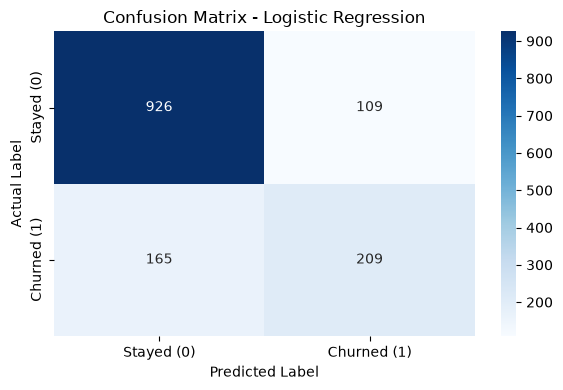

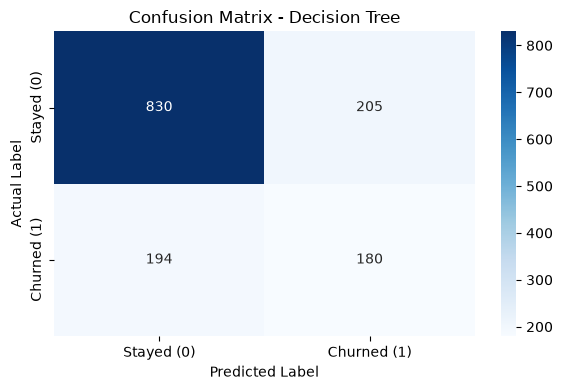

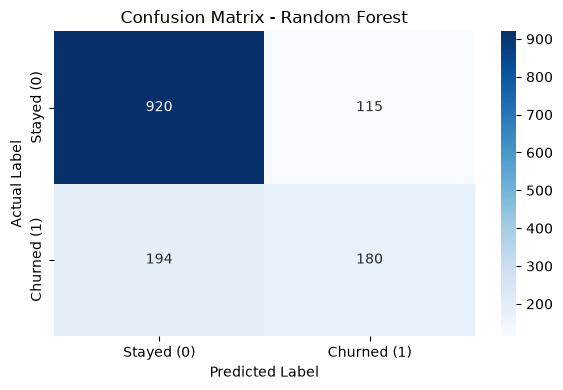

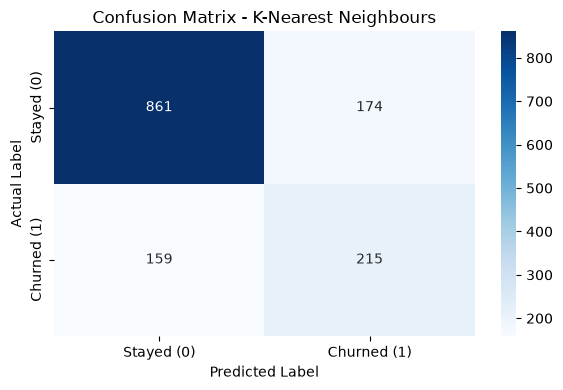

In [177]:
# Displaying the confusion matrix for all models

for name, cm in confusion_matrices.items():

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed (0)", "Churned (1)"],
        yticklabels=["Stayed (0)", "Churned (1)"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

# 7 The Best Algorithm and Why

In [178]:
# Identifying the model with the highest recal
best_recall_model = results_df.loc[
    results_df["Test Recall"].idxmax()
]

print("Model with highest test recall:")
display(best_recall_model)

Model with highest test recall:


Algorithm          K-Nearest Neighbours
Train Accuracy                    0.837
Test Accuracy                     0.764
Accuracy Gap                      0.073
Train Precision                   0.709
Test Precision                    0.553
Precision Gap                     0.156
Train Recall                      0.656
Test Recall                       0.575
Recall Gap                        0.081
Train F1                          0.681
Test F1                           0.564
F1 Gap                            0.117
Train ROC-AUC                     0.898
Test ROC-AUC                       0.79
ROC-AUC Gap                       0.108
Name: 3, dtype: object

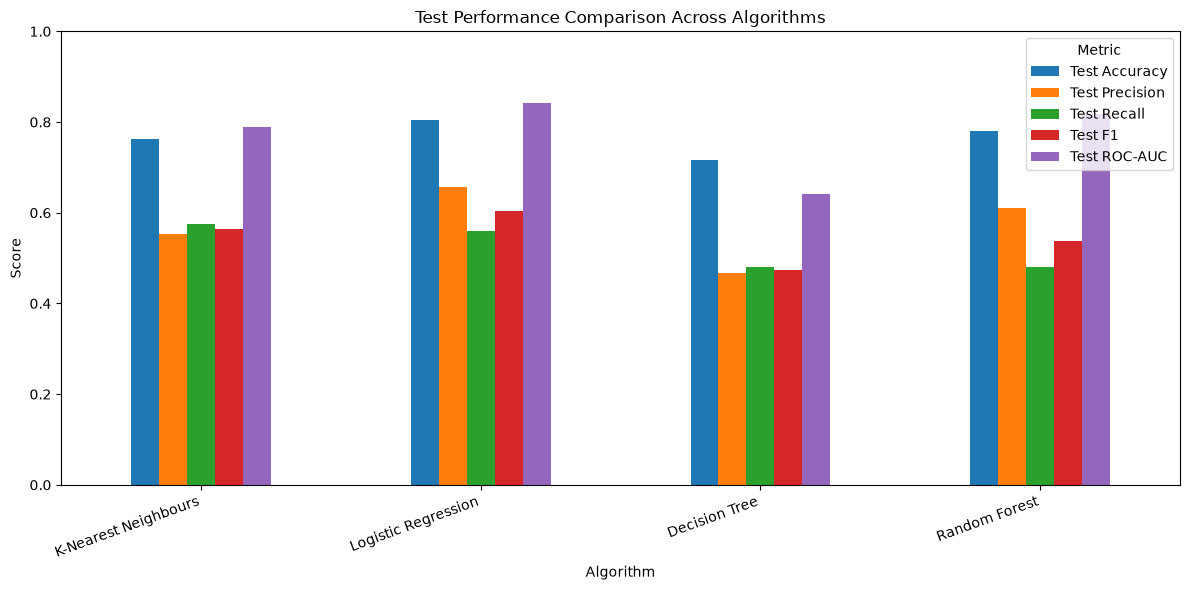

In [179]:
# Comparing the best Model visually
metrics_to_plot = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test ROC-AUC"
]

results_plot = results_df.set_index("Algorithm")[metrics_to_plot]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Test Performance Comparison Across Algorithms")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [180]:
# Checking for Overfitting
gap_columns = [
    "Accuracy Gap",
    "Precision Gap",
    "Recall Gap",
    "F1 Gap",
    "ROC-AUC Gap"
]

display(
    results_df[
        ["Algorithm"] + gap_columns
    ].round(3)
)

,Algorithm,Accuracy Gap,Precision Gap,Recall Gap,F1 Gap,ROC-AUC Gap
3,K-Nearest Neighbours,0.073,0.156,0.081,0.117,0.108
0,Logistic Regression,0.000,0.004,-0.008,-0.003,0.007
1,Decision Tree,0.281,0.532,0.512,0.522,0.359
2,Random Forest,0.217,0.387,0.514,0.458,0.182


In [181]:
# Tuning the models using cross-validation
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Defining the Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Defining the parameters to test
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__class_weight": [None, "balanced"]
}

# Setting up stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Searching for a model with high recall
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fitting using training data only
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation recall:")
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}

Best cross-validation recall:
0.7725752508361203


In [182]:
# Evaluatinf the tuned model by using the hold out test set
from sklearn.metrics import classification_report

best_rf = grid_search.best_estimator_

# Final test predictions
y_test_pred_rf = best_rf.predict(X_test)

# Test probabilities
y_test_proba_rf = best_rf.predict_proba(X_test)[:, 1]

print("Tuned Random Forest Test Results")

print("\nAccuracy:")
print(accuracy_score(y_test, y_test_pred_rf))

print("\nPrecision:")
print(precision_score(
    y_test,
    y_test_pred_rf,
    zero_division=0
))

print("\nRecall:")
print(recall_score(
    y_test,
    y_test_pred_rf,
    zero_division=0
))

print("\nF1-score:")
print(f1_score(
    y_test,
    y_test_pred_rf,
    zero_division=0
))

print("\nROC-AUC:")
print(roc_auc_score(
    y_test,
    y_test_proba_rf
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_rf,
    labels=[0, 1]
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_rf,
    zero_division=0
))

Tuned Random Forest Test Results

Accuracy:
0.7537260468417317

Precision:
0.5243243243243243

Recall:
0.7780748663101604

F1-score:
0.6264800861141012

ROC-AUC:
0.8414025162107004

Confusion Matrix:
[[771 264]
 [ 83 291]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.82      1035
           1       0.52      0.78      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



# 7 Best algorithm and why

After comparing the four machine learning models, **Logistic Regression** was selected as the best overall model.

It achieved a test accuracy of **80.6%**, precision of **65.7%**, F1-score of **60.4%**, and ROC-AUC of **84.2%**. These results indicate that it provides the best overall balance of predictive performance among the models tested.

Although K-Nearest Neighbours achieved a slightly higher recall of 57.5%, Logistic Regression performed better on the other reported test metrics. Therefore, Logistic Regression is the preferred baseline model for predicting customer churn.


## 8. Conclusion

This project used machine learning to predict customer churn in a telecommunications company. Four classification models were trained and evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrixes.

Logistic Regression achieved the best overall test performance, with an accuracy of 80.6% and ROC-AUC of 84.2%. The model could help the company identify customers who may leave and target retention campaigns more effectively.

However, the model still misses some customers who churn. Further improvements could include tuning the model, adjusting the prediction threshold, and testing additional features to improve churn detection.
